# 01 · Inventory of the data package

What is in `reference.zip` and `strata.zip`? We read only the **Parquet footers** straight from the zip members (no extraction), so this runs in seconds.

*Replaces the former `analysis_scripts/01_inventory.py`.*

In [1]:
import json, pathlib, zipfile
import pandas as pd, pyarrow.parquet as pq, matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
DATA, OUT = ROOT / "data", ROOT / "analysis_outputs"

rows = []
for zname in ("reference.zip", "strata.zip"):
    z = zipfile.ZipFile(DATA / zname)
    for info in z.infolist():
        if not info.filename.endswith(".parquet"):
            continue
        with z.open(info) as fh:                       # stored member -> seekable -> only the footer is read
            f = pq.ParquetFile(fh)
            rows.append(dict(zip=zname, path=info.filename, size_mb=info.file_size / 1e6,
                             rows=f.metadata.num_rows, n_cols=len(f.schema_arrow.names)))
inv = pd.DataFrame(rows)
inv["region"] = inv.path.str.split("/").str[1]
inv["layer"] = inv.path.str.extract(r"overture-([a-z-]+)\.parquet")[0]
print(len(inv), "parquet files;", round(inv.size_mb.sum() / 1e3, 2), "GB")
inv.sort_values("size_mb", ascending=False).head(12)

179 parquet files; 5.12 GB


,zip,path,size_mb,rows,n_cols,region,layer
29,reference.zip,reference/south-central-tx/south-central-tx-ov...,1269.949045,11463801,26,south-central-tx,buildings
33,reference.zip,reference/south-central-tx/south-central-tx-ov...,783.316505,4122701,23,south-central-tx,roads-unfiltered
15,reference.zip,reference/maricopa-az/maricopa-az-overture-bui...,324.720762,2908224,26,maricopa-az,buildings
34,reference.zip,reference/south-central-tx/south-central-tx-ov...,299.751270,1937009,23,south-central-tx,roads
1,reference.zip,reference/eastern-ok/eastern-ok-overture-build...,298.882068,2551694,26,eastern-ok,buildings
19,reference.zip,reference/maricopa-az/maricopa-az-overture-roa...,262.146919,1170165,23,maricopa-az,roads-unfiltered
111,strata.zip,strata/national/national-census-tracts.parquet,224.006890,85396,12,national,NaN
5,reference.zip,reference/eastern-ok/eastern-ok-overture-roads...,192.989343,1037555,23,eastern-ok,roads-unfiltered
31,reference.zip,reference/south-central-tx/south-central-tx-ov...,179.937096,1300334,19,south-central-tx,pois
26,reference.zip,reference/northern-ca/northern-ca-overture-roa...,157.211249,479596,23,northern-ca,roads-unfiltered


**Comment:** the package is dominated by a few Overture layers (buildings, roads). The strata tables are tiny by comparison.

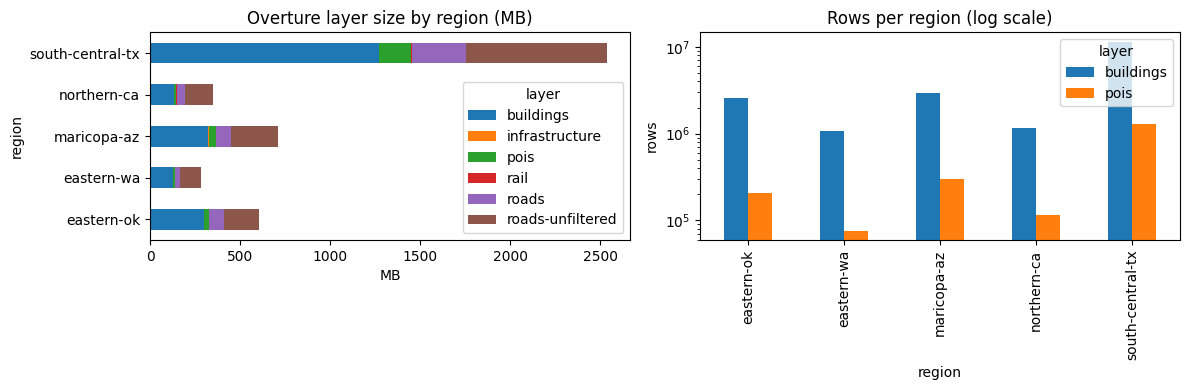

In [2]:
ov = inv.dropna(subset=["layer"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ov.pivot_table(index="region", columns="layer", values="size_mb", aggfunc="sum").plot.barh(stacked=True, ax=ax[0])
ax[0].set_title("Overture layer size by region (MB)"); ax[0].set_xlabel("MB")
ov.pivot_table(index="region", columns="layer", values="rows", aggfunc="sum")[["buildings", "pois"]].plot.bar(ax=ax[1], logy=True)
ax[1].set_title("Rows per region (log scale)"); ax[1].set_ylabel("rows")
plt.tight_layout(); plt.show()

**Comment:** South-Central TX is by far the largest region (about 11M buildings, 1.3M POIs), which is why it dominates any pooled RMSE.

In [3]:
inv.to_csv(OUT / "inventory_parquet_footers.csv", index=False)
print("saved", OUT / "inventory_parquet_footers.csv")

saved C:\Users\prajw\OneDrive\Documents\5 sem\ada\MapEquityChallenge\analysis_outputs\inventory_parquet_footers.csv
